# Step 4 — 1D Burgers' Equation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step04_burgers_1d.ipynb)

*Part of [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md), after Lorena Barba's CFD Python; moved from somax's tutorial series.*

Steps 1--3 introduced convection and diffusion separately. Now we bring them together in **Burgers' equation** — the simplest PDE that exhibits the competition between nonlinear steepening and viscous smoothing. This balance is at the heart of turbulence and is the reason Burgers' equation has been called "the hydrogen atom of fluid dynamics."

**What you'll learn:**

1. How convection and diffusion compete to shape the solution
2. How viscosity controls the balance (low $\nu$: shocks; high $\nu$: smooth decay)
3. How to compare solutions at different viscosities side by side
4. How to compute $\partial \mathcal{L} / \partial \nu$ for parameter estimation

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

$$
\frac{\partial u}{\partial t} + u \frac{\partial u}{\partial x} = \nu \frac{\partial^2 u}{\partial x^2}
$$

The left-hand side is the nonlinear convection from Step 2 (inviscid Burgers). The right-hand side is the diffusion from Step 3. The dimensionless ratio that controls the balance is the **Reynolds number**:

$$
\mathrm{Re} = \frac{U \ell}{\nu}
$$

where $U$ is a characteristic velocity and $\ell$ a characteristic length. At high Re the nonlinear term dominates (sharp gradients, near-shocks). At low Re diffusion dominates (smooth, decaying profiles).

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$ is the spatial coordinate (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$ | spatial coordinate | $\mathbb{R}$ |
| $t \in [t_0, t_1]$ | time | $\mathbb{R}$ |
| $u(x, t)$ | the velocity field, advected by itself | $\mathbb{R}$ |
| $u_0(x)$ | initial condition, a Gaussian bump with centre $\mu_0$ and width $\sigma_0$ | $\mathbb{R}$ |
| $\nu$ | viscosity, the model's differentiable parameter | $\mathbb{R}_{>0}$ |
| $\mathrm{Re}$, $U$, $\ell$ | Reynolds number, characteristic velocity and characteristic length | $\mathbb{R}_{>0}$ |
| $L_x$ | domain length | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x}$ | number of interior grid cells | count |
| $\Delta x = L_x / N_{\Omega_x}$, $\Delta t$ | grid spacing and time step | $\mathbb{R}_{>0}$ |
| $u_n$ | the field in cell $n$; the vector of all cells, with ghosts, has length $N_{\Omega_x} + 2$ | $\mathbb{R}$ |
| $E(t)$ | energy | $\mathbb{R}_{\ge 0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |
| $u^\text{obs}(x)$, $\nu^\text{true}$ | the observed final profile and the viscosity that generated it | $\mathbb{R}$, $\mathbb{R}_{>0}$ |
| $N_\nu$ | number of viscosity values compared or swept | count |

## Grid layout and boundary conditions

The field $u$ lives at T-points, in an array with one ghost cell at each end around the $N_{\Omega_x}$ interior cells; the [C-grid page](cgrid_and_boundaries.ipynb) explains the layout. The upwind flux reconstruction computes the advection term $\partial (u^2 / 2) / \partial x$ at the U-points between neighbouring T-points.

Burgers' equation combines both **advection** (upwind reconstruction at U-points) and **diffusion** (Laplacian stencil at T-points). The Laplacian $(u_{n+1} - 2 u_n + u_{n-1}) / \Delta x^2$ reaches both neighbours, so ghost cells are essential for both terms.

**Periodic BCs** copy the last interior value into the opposite ghost cell, $u_0 = u_{N_{\Omega_x}}$ and $u_{N_{\Omega_x} + 1} = u_1$, so the domain wraps around and both advection and diffusion operate seamlessly across the boundary.

In [2]:
import diffrax as dfx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

`Burgers1D` combines upwind advection with centred diffusion. The viscosity $\nu$ is a differentiable parameter.

In [4]:
# Shapes: N_Ωx = 200 interior cells

num_cells = 200
domain_length = 4.0
viscosity = 0.05

# today (sesmax_core)
model = sxt.Burgers1D.create(nx=num_cells, Lx=domain_length, nu=viscosity)

print(f"Grid: Nx={model.grid.Nx}, dx={model.grid.dx:.4f}")
print(f"Viscosity nu = {float(model.params.nu)}")
print(f"Advection method: {model.method}")

Grid: Nx=202, dx=0.0200
Viscosity nu = 0.05000000074505806
Advection method: upwind1


## 2. Initial condition

A Gaussian bump centred at $\mu_0 = 1.5$ with width $\sigma_0 = 0.3$,

$$
u_0(x) = \exp\left(-\frac{(x - \mu_0)^2}{2 \sigma_0^2}\right)
$$

The positive amplitude means the nonlinear term will try to steepen the right flank while diffusion resists.

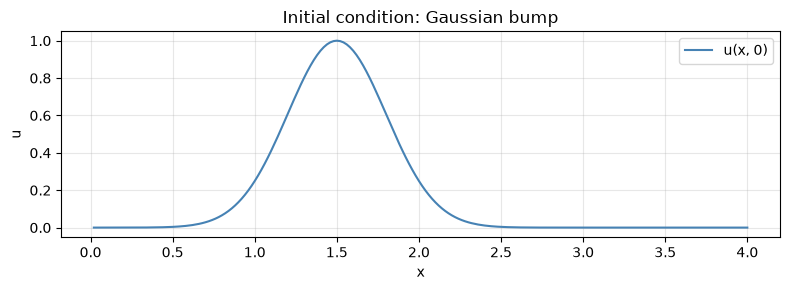

In [5]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

interior = slice(1, -1)
bump_centre = 1.5
bump_width = 0.3

# xₙ = n Δx
position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_Ωx + 2,)
# zₙ = (xₙ − μ₀) / σ₀
standardised = (position - bump_centre) / bump_width  # → (N_Ωx + 2,)
# u₀(x) = exp(−z² / 2)
initial_u = jnp.exp(-0.5 * standardised**2)  # → (N_Ωx + 2,)

# today (sesmax_core)
initial_state = sxt.Burgers1DState(u=initial_u)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(
    position[interior],
    initial_u[interior],
    color="steelblue",
    lw=1.5,
    label="u(x, 0)",
)
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("Initial condition: Gaussian bump")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Forward simulation — the Burgers dynamics

The initial steepening (convection) is gradually balanced by diffusion, producing a characteristic asymmetric profile.

In [6]:
# Shapes: N_T = 6 saved snapshots; N_Ωx + 2 = 202 cells with the ghosts

start_time = 0.0
end_time = 0.8
time_step = 0.001
save_times = jnp.array([0.0, 0.05, 0.1, 0.2, 0.4, 0.8])  # → (N_T,)

# today (sesmax_core, diffrax)
# u(x, tₖ) for each saved time
solution = model.integrate(  # u → (N_T, N_Ωx + 2)
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

print(f"Trajectory shape: u={solution.ys.u.shape}")

Trajectory shape: u=(6, 202)


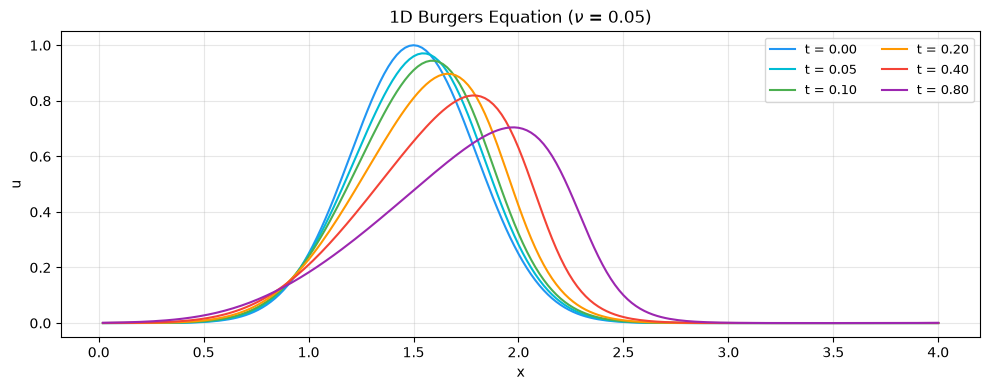

In [7]:
snapshot_colours = ["#2196F3", "#00BCD4", "#4CAF50", "#FF9800", "#F44336", "#9C27B0"]

fig, ax = plt.subplots(figsize=(10, 4))
for snapshot, save_time in enumerate(save_times):
    ax.plot(
        position[interior],
        solution.ys.u[snapshot, interior],
        color=snapshot_colours[snapshot],
        lw=1.5,
        label=f"t = {float(save_time):.2f}",
    )
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title(f"1D Burgers Equation ($\\nu$ = {viscosity})")
ax.legend(fontsize=9, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Notice the initial rightward steepening (Steps 1--2) followed by overall decay (Step 3). The profile develops the classic Burgers asymmetry: a steep front on the right and a gentle tail on the left.

## 4. Low vs. high viscosity comparison

The viscosity $\nu$ controls the balance between steepening and smoothing. We compare three values to see the effect.

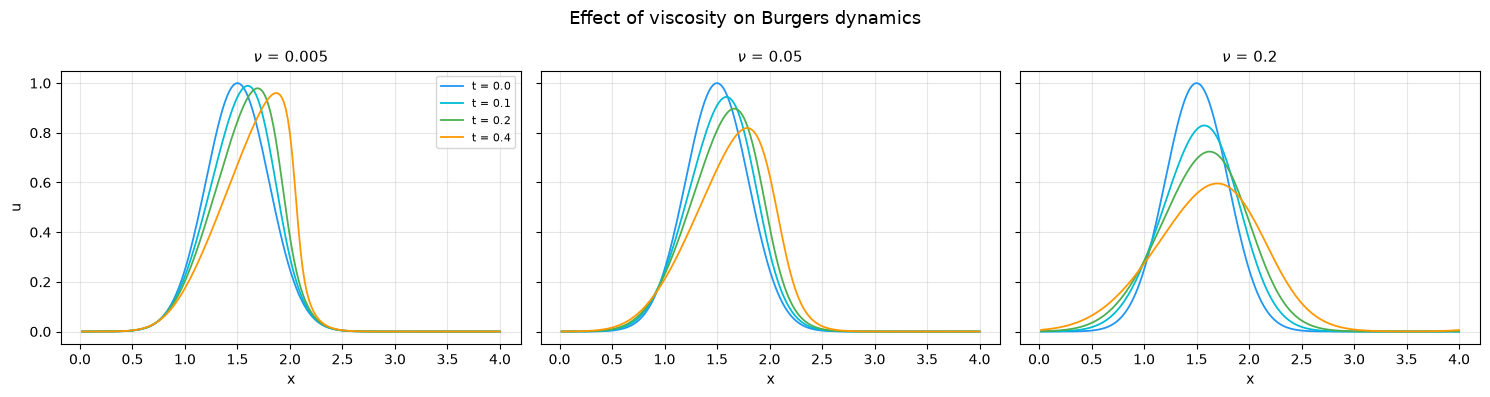

In [8]:
# Shapes: N_ν = 3 viscosities; N_T = 4 saved snapshots; N_Ωx + 2 = 202 cells

viscosities = [0.005, 0.05, 0.2]  # → (N_ν,)
viscosity_colours = ["#F44336", "#4CAF50", "#2196F3"]
viscosity_labels = [f"$\\nu$ = {value}" for value in viscosities]

compare_time = 0.4
compare_times = jnp.array([0.0, 0.1, 0.2, 0.4])  # → (N_T,)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for index, value in enumerate(viscosities):
    # today (sesmax_core)
    viscosity_model = sxt.Burgers1D.create(nx=num_cells, Lx=domain_length, nu=value)
    # today (sesmax_core, diffrax)
    # u(x, tₖ; ν) for each saved time
    viscosity_solution = viscosity_model.integrate(  # u → (N_T, N_Ωx + 2)
        initial_state,
        t0=0.0,
        t1=compare_time,
        dt=0.001,
        saveat=dfx.SaveAt(ts=compare_times),
    )
    ax = axes[index]
    for snapshot, save_time in enumerate(compare_times):
        ax.plot(
            position[interior],
            viscosity_solution.ys.u[snapshot, interior],
            color=snapshot_colours[snapshot],
            lw=1.3,
            label=f"t = {float(save_time):.1f}",
        )
    ax.set_xlabel("x")
    ax.set_title(viscosity_labels[index], fontsize=11)
    ax.grid(True, alpha=0.3)
    if index == 0:
        ax.set_ylabel("u")
        ax.legend(fontsize=8)

fig.suptitle("Effect of viscosity on Burgers dynamics", fontsize=13)
plt.tight_layout()
plt.show()

**Low viscosity** ($\nu = 0.005$): the nonlinear term dominates, producing a sharp front that resembles a shock.

**Medium viscosity** ($\nu = 0.05$): steepening and diffusion are balanced — the classic Burgers profile.

**High viscosity** ($\nu = 0.2$): diffusion dominates, and the profile decays almost symmetrically (nearly pure diffusion).

## 5. Side-by-side at a fixed time

Overlaying the three viscosities at $t = 0.4$ makes the contrast even clearer.

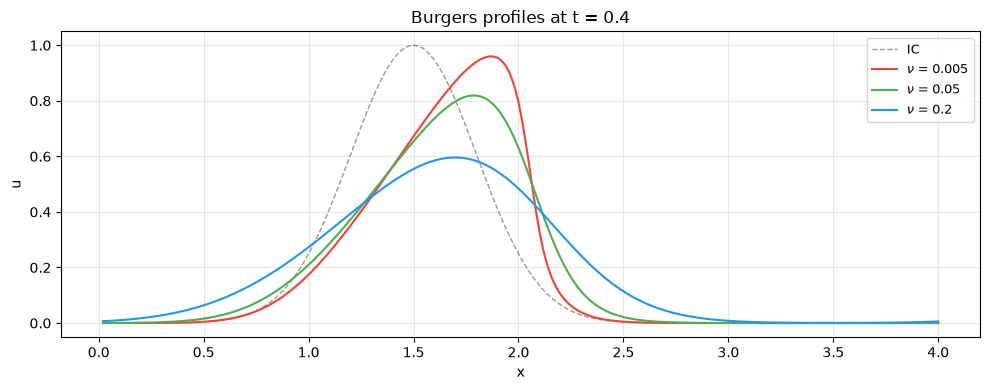

In [9]:
# Shapes: N_ν = 3 viscosities; N_Ωx + 2 = 202 cells with the ghosts

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(position[interior], initial_u[interior], "k--", lw=1.0, alpha=0.4, label="IC")

for index, value in enumerate(viscosities):
    # today (sesmax_core)
    viscosity_model = sxt.Burgers1D.create(nx=num_cells, Lx=domain_length, nu=value)
    # today (sesmax_core, diffrax)
    # u(x, t) at the compare time, for this ν
    viscosity_solution = viscosity_model.integrate(  # u → (1, N_Ωx + 2)
        initial_state,
        t0=0.0,
        t1=compare_time,
        dt=0.001,
        saveat=dfx.SaveAt(t1=True),
    )
    ax.plot(
        position[interior],
        viscosity_solution.ys.u[0, interior],
        color=viscosity_colours[index],
        lw=1.5,
        label=viscosity_labels[index],
    )

ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title(f"Burgers profiles at t = {compare_time}")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Energy evolution

Energy always decays for Burgers (the diffusion term dissipates it). Higher viscosity means faster decay,

$$
E(t) = \frac{1}{2} \int_0^{L_x} u(x, t)^2 \mathrm{d}x
$$

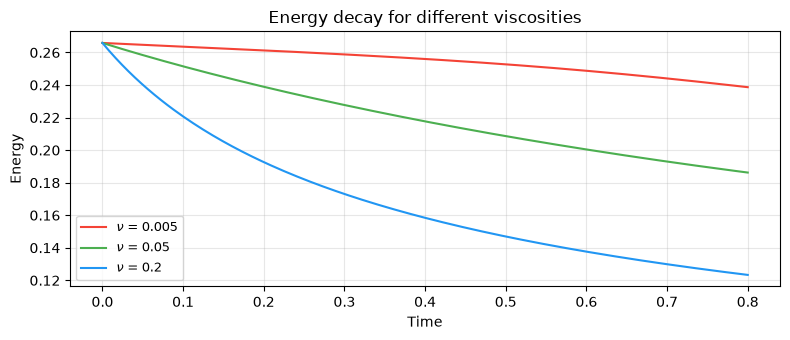

In [10]:
# Shapes: N_ν = 3 viscosities; N_T = 200 saved snapshots; N_Ωx + 2 = 202 cells

# tₖ, k = 0, …, N_T − 1
dense_times = jnp.linspace(start_time, end_time, 200)  # → (N_T,)

fig, ax = plt.subplots(figsize=(8, 3.5))

for index, value in enumerate(viscosities):
    # today (sesmax_core)
    viscosity_model = sxt.Burgers1D.create(nx=num_cells, Lx=domain_length, nu=value)
    # today (sesmax_core, diffrax)
    # u(x, tₖ; ν) for each saved time
    viscosity_solution = viscosity_model.integrate(  # u → (N_T, N_Ωx + 2)
        initial_state,
        t0=start_time,
        t1=end_time,
        dt=0.001,
        saveat=dfx.SaveAt(ts=dense_times),
    )
    # today (sesmax_core)
    # E(tₖ) = (Δx / 2) Σₙ uₙ(tₖ)²
    diagnostics = jax.vmap(viscosity_model.diagnose)(viscosity_solution.ys)
    viscosity_energy = diagnostics.energy  # → (N_T,)
    ax.plot(
        dense_times,
        viscosity_energy,
        color=viscosity_colours[index],
        lw=1.5,
        label=viscosity_labels[index],
    )

ax.set_xlabel("Time")
ax.set_ylabel("Energy")
ax.set_title("Energy decay for different viscosities")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Differentiability demo — gradient w.r.t. viscosity

Suppose we observe a diffusing, steepening profile and want to infer the viscosity. We compute $\partial \mathcal{L} / \partial \nu$ where $\mathcal{L}$ measures the mismatch between the predicted and observed final profile at $t_1 = 0.4$,

$$
\mathcal{L}(\nu) = \frac{1}{N_{\Omega_x}} \sum_{n=1}^{N_{\Omega_x}} \left(u_n(t_1; \nu) - u_n^\text{obs}\right)^2
$$

The observation is generated with the true viscosity $\nu^\text{true} = 0.08$.

In [11]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

true_viscosity = 0.08

# today (sesmax_core)
true_model = sxt.Burgers1D.create(nx=num_cells, Lx=domain_length, nu=true_viscosity)
# today (sesmax_core, diffrax)
# u(x, t₁; ν_true)
true_solution = true_model.integrate(  # u → (1, N_Ωx + 2)
    initial_state, t0=0.0, t1=0.4, dt=0.001, saveat=dfx.SaveAt(t1=True)
)
observed_u = true_solution.ys.u[0]  # → (N_Ωx + 2,)


# today (equinox)
@eqx.filter_grad
def grad_wrt_model(model):
    """Gradient of the MSE loss ℒ(ν) with respect to every float leaf of the model."""
    # today (sesmax_core, diffrax)
    # u(x, t₁; ν)
    final_solution = model.integrate(initial_state, t0=0.0, t1=0.4, dt=0.001)
    predicted_u = final_solution.ys.u[-1]  # → (N_Ωx + 2,)
    # rₙ = uₙ(t₁; ν) − uₙᵒᵇˢ
    residual = predicted_u[interior] - observed_u[interior]  # → (N_Ωx,)
    # ℒ(ν) = (1/N_Ωx) Σₙ rₙ²
    loss = jnp.mean(residual**2)  # → ()
    return loss


# the gradient at our initial guess ν = 0.05
# ∂ℒ/∂ν
model_grads = grad_wrt_model(model)

print("--- Gradient w.r.t. model parameters ---")
print(f"  Current nu = {float(model.params.nu):.3f}")
print("  True nu    = 0.08")
print(f"  dL/d(nu)   = {float(model_grads.params.nu):.6f}")
print()
print("A negative gradient means increasing nu (toward the true value)")
print("would decrease the loss — the gradient points in the right direction.")

--- Gradient w.r.t. model parameters ---
  Current nu = 0.050
  True nu    = 0.08
  dL/d(nu)   = -0.044098

A negative gradient means increasing nu (toward the true value)
would decrease the loss — the gradient points in the right direction.


### Gradient landscape

We can sweep over $\nu$ values to see the full loss landscape and verify that the gradient direction is consistent.

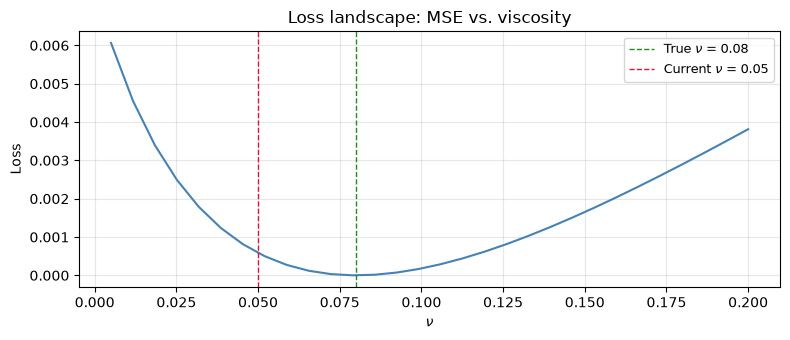

In [12]:
# Shapes: N_ν = 30 swept viscosities; N_Ωx = 200 interior cells

viscosity_sweep = jnp.linspace(0.005, 0.2, 30)  # → (N_ν,)


def loss_for_viscosity(value):
    """MSE ℒ(ν) at one viscosity, for the sweep."""
    # today (sesmax_core)
    sweep_model = sxt.Burgers1D.create(nx=num_cells, Lx=domain_length, nu=float(value))
    # today (sesmax_core, diffrax)
    # u(x, t₁; ν)
    sweep_solution = sweep_model.integrate(initial_state, t0=0.0, t1=0.4, dt=0.001)
    predicted_u = sweep_solution.ys.u[-1]  # → (N_Ωx + 2,)
    # rₙ = uₙ(t₁; ν) − uₙᵒᵇˢ
    residual = predicted_u[interior] - observed_u[interior]  # → (N_Ωx,)
    # ℒ(ν) = (1/N_Ωx) Σₙ rₙ²
    loss = jnp.mean(residual**2)  # → ()
    return loss


losses = jnp.array([loss_for_viscosity(value) for value in viscosity_sweep])  # → (N_ν,)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(viscosity_sweep, losses, color="steelblue", lw=1.5)
ax.axvline(0.08, color="forestgreen", ls="--", lw=1.0, label="True $\\nu$ = 0.08")
ax.axvline(
    float(model.params.nu),
    color="crimson",
    ls="--",
    lw=1.0,
    label="Current $\\nu$ = 0.05",
)
ax.set_xlabel("$\\nu$")
ax.set_ylabel("Loss")
ax.set_title("Loss landscape: MSE vs. viscosity")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary of 1D models

| Step | PDE | Key physics | sesmax model |
|------|-----|-------------|-------------|
| 1 | $u_t + c u_x = 0$ | Translation at constant speed | `LinearConvection1D` |
| 2 | $u_t + u u_x = 0$ | Self-steepening, shocks | `NonlinearConvection1D` |
| 3 | $u_t = \nu u_{xx}$ | Smoothing, energy decay | `Diffusion1D` |
| 4 | $u_t + u u_x = \nu u_{xx}$ | Steepening vs. smoothing | `Burgers1D` |

All four models share the same API contract:

- `Model.create(...)` — factory with physical parameters
- `model.integrate(state0, t0, t1, dt, saveat=...)` — forward sim
- `model.diagnose(state)` — on-demand diagnostics
- `eqx.filter_grad(loss)(model)` — differentiable w.r.t. parameters

**What comes next:** These 1D building blocks extend naturally to 2D. Steps 5--8 will introduce 2D convection, diffusion, and the cavity flow problem, building toward the full Navier-Stokes equations.